# SET 10

## __NOTE:__  _Update this with fhe filenames and folder path_

In [1]:
import pandas as pd

# Files names in order (V1, V2, etc)
filenames = [
    "metrics_log_power_1791934273.csv",
    "metrics_log_power_1791934772.csv",
    "metrics_log_power_1791935186.csv",
    "metrics_log_power_1791935714.csv",
    "metrics_log_power_1791936100.csv",
    "metrics_log_power_1791936607.csv",
]

# file path for the folder where the files are stored:
file_path = "../Metrics/MQ3_logs_10-13-2026/"

### &rarr; __CHECKING DATA:__

In [2]:
# STORING DATA FRAMES
dfs = {}
for i, filename in enumerate(filenames, start=1):
    full_path = file_path + filename
    dfs[f"v{i}"] = pd.read_csv(full_path)

In [3]:
dfs["v1"]

,id_line,Timestamp,Elapsed (s),Level (%),Voltage (mV),Temp (C),Charge Counter (uAh),Calculated Current (mA),Calculated Power (mW),Accumulated Power (mWh),...,Foreground App,Media App,Video Title,Title Source,Playback State,Video Clock,Video Session,Video Position (s),Video Position (mm:ss),Position Source
0,1,2026-10-13 18:31:13,0.31,100,4264,30.0,4964064,2476.89,10561.46,3.755,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Not playing,Idle,0,NaN,NaN,NaN
1,2,2026-10-13 18:31:14,1.59,100,4264,30.0,4964064,2476.89,10561.46,7.217,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Not playing,Idle,0,NaN,NaN,NaN
2,3,2026-10-13 18:31:15,2.77,100,4264,30.0,4964064,2476.89,10561.46,9.417,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Not playing,Idle,0,NaN,NaN,NaN
3,4,2026-10-13 18:31:16,3.52,100,4264,30.0,4964064,2476.89,10561.46,11.940,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Not playing,Idle,0,NaN,NaN,NaN
4,5,2026-10-13 18:31:17,4.38,100,4264,30.0,4964064,2476.89,10561.46,14.639,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Not playing,Idle,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
441,442,2026-10-13 18:38:35,442.05,95,4217,40.0,4750920,0.00,0.00,898.626,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Not playing,Stopped,0,NaN,NaN,NaN
442,443,2026-10-13 18:38:36,443.19,95,4217,40.0,4750920,0.00,0.00,898.626,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Not playing,Stopped,0,NaN,NaN,NaN
443,444,2026-10-13 18:38:37,443.99,95,4217,40.0,4750920,0.00,0.00,898.626,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Not playing,Stopped,0,NaN,NaN,NaN
444,445,2026-10-13 18:38:38,445.02,95,4217,40.0,4750920,0.00,0.00,898.626,...,com.google.android.apps.youtube.vr.oculus,com.google.android.apps.youtube.vr.oculus,NaN,NaN,Not playing,Stopped,0,NaN,NaN,NaN


In [4]:
# CHECKING MANUAL CONTROL RESULTS:
for i, filename in enumerate(filenames, start=1):
    df = dfs[f"v{i}"]
    total_seconds = (df["Video Session"] == 1).sum()
    minutes = total_seconds // 60
    seconds = total_seconds % 60

    print(f"v{i} Total time: {minutes}:{seconds:02d}")

v1 Total time: 6:19
v2 Total time: 5:36
v3 Total time: 6:40
v4 Total time: 3:37
v5 Total time: 6:17
v6 Total time: 4:30


### TABLES IN __DFS{}__ DICTIONARY:

In [5]:
# CHECKING MANUAL CONTROL RESULTS:
for i, filename in enumerate(filenames, start=1):
    df = dfs[f"v{i}"]
    total_seconds = (df["Video Session"] == 1).sum()
    minutes = total_seconds // 60
    seconds = total_seconds % 60

    print(f"v{i} Total time: {minutes}:{seconds:02d}")

v1 Total time: 6:19
v2 Total time: 5:36
v3 Total time: 6:40
v4 Total time: 3:37
v5 Total time: 6:17
v6 Total time: 4:30


### &rarr; __PLOTTING RESULTS:__

In [6]:
import matplotlib.pyplot as plt

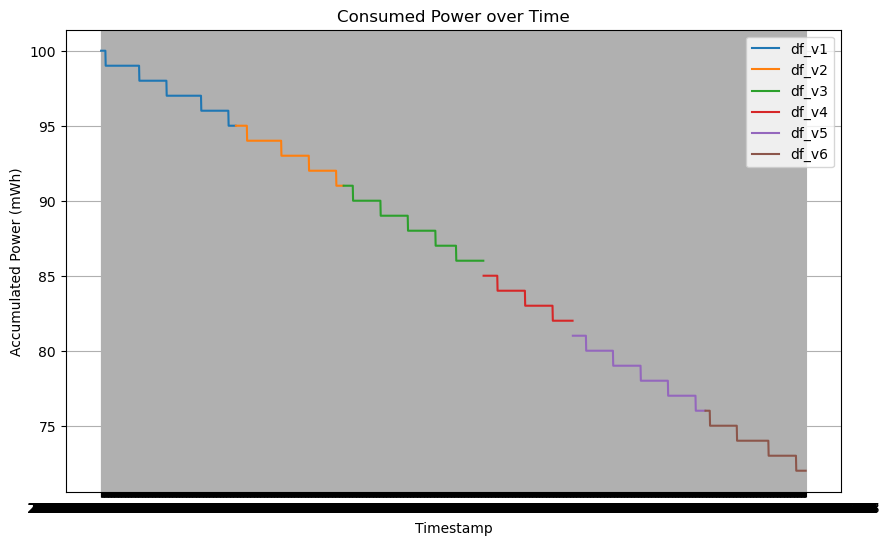

In [7]:
plt.figure(figsize=(10, 6))

for key, df in dfs.items():
    df.columns = df.columns.str.strip()
    plt.plot(df["Timestamp"], df["Level (%)"], label=f"df_{key}")

# Add titles, labels, and legend
plt.title("Consumed Power over Time")
plt.xlabel("Timestamp")
plt.ylabel("Accumulated Power (mWh)")
plt.legend()
plt.grid(True)

plt.show()

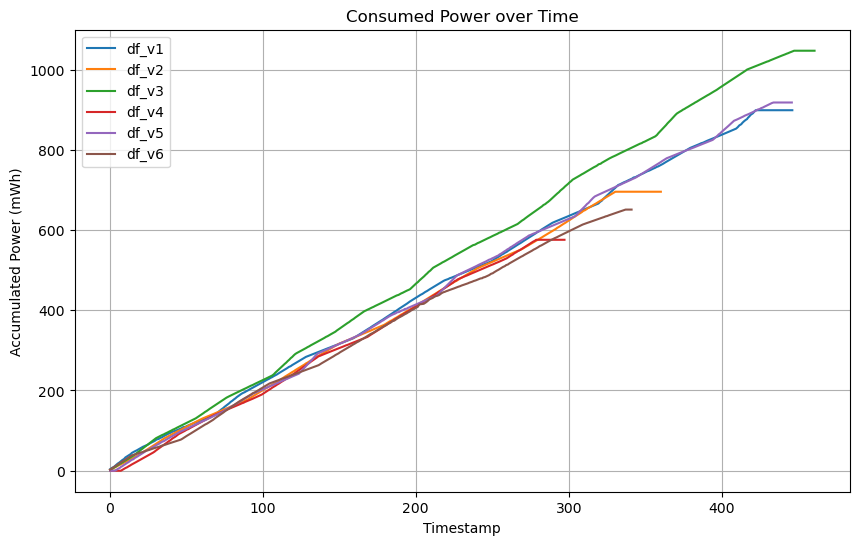

In [8]:
plt.figure(figsize=(10, 6))

for key, df in dfs.items():
    df.columns = df.columns.str.strip()
    plt.plot(df["Elapsed (s)"], df["Accumulated Power (mWh)"], label=f"df_{key}")

# Add titles, labels, and legend
plt.title("Consumed Power over Time")
plt.xlabel("Timestamp")
plt.ylabel("Accumulated Power (mWh)")
plt.legend()
plt.grid(True)

plt.show()

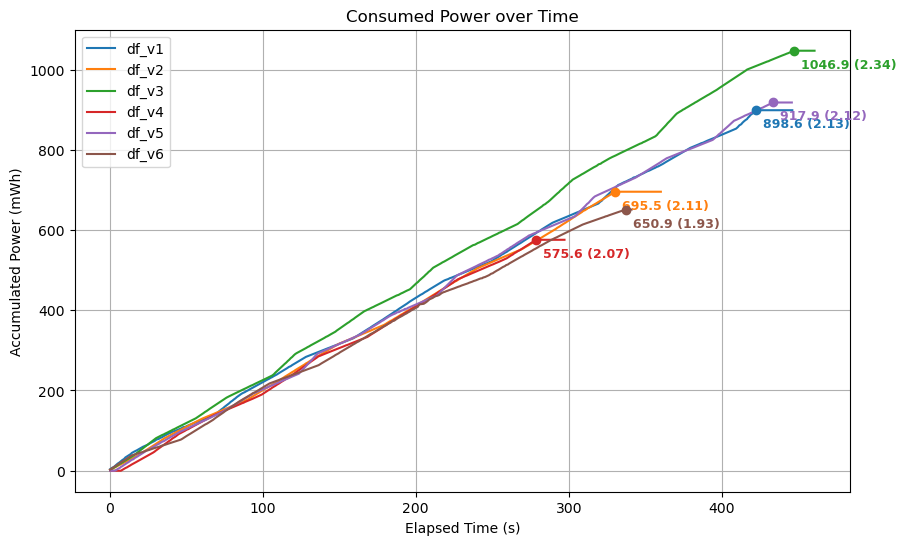

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for key, df in dfs.items():
    df.columns = df.columns.str.strip()
    x = df["Elapsed (s)"]
    y = df["Accumulated Power (mWh)"]
    
    # Plot the line and capture the line object to get its color
    line, = plt.plot(x, y, label=f"df_{key}")
    
    # Find the index and coordinates of the highest y-value
    max_idx = y.idxmax()
    max_x = x.loc[max_idx]
    max_y = y.loc[max_idx]
    
    # Calculate max value / max elapsed time
    ratio = max_y / max_x if max_x != 0 else 0
    
    # Add a matching dot at the highest point
    plt.scatter(max_x, max_y, color=line.get_color(), zorder=5)
    
    # Annotate with the value and ratio on the same line
    plt.annotate(
        f"{max_y:.1f} ({ratio:.2f})", 
        (max_x, max_y),
        textcoords="offset points",
        xytext=(5, -10),      # 10 points to the right, 8 points up
        ha='left',           # Aligned to the left so text extends to the right
        va='center',         # Vertically centered relative to the dot
        color=line.get_color(), 
        fontsize=9, 
        weight='bold'
    )

# Add titles, labels, and legend
plt.title("Consumed Power over Time")
plt.xlabel("Elapsed Time (s)")
plt.ylabel("Accumulated Power (mWh)")
plt.legend()
plt.grid(True)

plt.show()

### &rarr; __Real Conditions (vs Target)__:

In [11]:
summary_list = []

for key, df in dfs.items():
    summary_list.append({
        "DataFrame": f"{key}",  # Using key (or i if you have an index counter)
        "Initial Battery Level": df["Level (%)"].max(),
        "Avg Volume (%)": df["Volume (%)"].mean(),
        "Avg Brightness (%)": df["Brightness (%)"].mean(),
    })

# Create a final summary DataFrame
summary_df = pd.DataFrame(summary_list)
print(summary_df)

  DataFrame  Initial Battery Level  Avg Volume (%)  Avg Brightness (%)
0        v1                    100       38.925785                61.6
1        v2                     95       20.167500                61.6
2        v3                     91       26.700000                61.6
3        v4                     85       26.609153                61.6
4        v5                     81       26.700000                61.6
5        v6                     76       26.700000                61.6
